In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd

In [3]:
# Locate all segmentation image-mask pairs

segmentation_path = r"C:\ML PROJECT\DATASET\Segmentation"

mask_files = glob.glob(
    os.path.join(segmentation_path, "**", "*_mask.png"),
    recursive=True
)

print("Total mask files:", len(mask_files))

# Check a few files
print("\nSample mask files:")

for mask_path in mask_files[:5]:
    print(mask_path)

Total mask files: 2192

Sample mask files:
C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1841_mask.png
C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1842_mask.png
C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1843_mask.png
C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1844_mask.png
C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1845_mask.png


In [4]:
# Generate numerical features from MRI images and segmentation masks

feature_data = []

for mask_path in mask_files:

    # Get corresponding MRI image
    image_path = mask_path.replace("_mask.png", ".png")

    if not os.path.exists(image_path):
        print("Image not found:", image_path)
        continue

    # Load MRI and mask
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image is None or mask is None:
        print("Could not load:", image_path)
        continue

    # Binary tumor mask
    binary_mask = (mask == 255).astype(np.uint8)

    # Tumor pixel count
    tumor_area = np.sum(binary_mask)

    # Total image pixels
    total_pixels = binary_mask.size

    # Tumor percentage
    tumor_percentage = (tumor_area / total_pixels) * 100

    # Find tumor coordinates
    y_coords, x_coords = np.where(binary_mask == 1)

    # Default values for images with no tumor pixels
    if len(x_coords) > 0:

        tumor_width = x_coords.max() - x_coords.min() + 1
        tumor_height = y_coords.max() - y_coords.min() + 1

        aspect_ratio = tumor_width / tumor_height

        # MRI intensity values inside tumor
        tumor_pixels = image[binary_mask == 1]

        mean_intensity = np.mean(tumor_pixels)
        std_intensity = np.std(tumor_pixels)
        min_intensity = np.min(tumor_pixels)
        max_intensity = np.max(tumor_pixels)

    else:

        tumor_width = 0
        tumor_height = 0
        aspect_ratio = 0

        mean_intensity = 0
        std_intensity = 0
        min_intensity = 0
        max_intensity = 0

    # Extract tumor type from folder name
    tumor_type = os.path.basename(os.path.dirname(mask_path))

    # Image filename
    image_name = os.path.basename(image_path)

    # Store features
    feature_data.append({
        "image_name": image_name,
        "tumor_type": tumor_type,
        "tumor_area": tumor_area,
        "tumor_percentage": tumor_percentage,
        "tumor_width": tumor_width,
        "tumor_height": tumor_height,
        "aspect_ratio": aspect_ratio,
        "mean_intensity": mean_intensity,
        "std_intensity": std_intensity,
        "min_intensity": min_intensity,
        "max_intensity": max_intensity
    })

# Convert to DataFrame
features_df = pd.DataFrame(feature_data)

print("Feature generation completed!")
print("Number of samples:", len(features_df))
print("\nFeatures:")
print(features_df.columns.tolist())

Feature generation completed!
Number of samples: 2192

Features:
['image_name', 'tumor_type', 'tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']


### Feature Engineering Justification

The project extracts geometric and intensity-based features from the segmented tumor region.

Tumor area represents the size of the tumor region, while tumor width and tumor height describe its spatial dimensions. Aspect ratio captures the shape relationship between the tumor's width and height.

The mean intensity, standard deviation, minimum intensity, and maximum intensity describe the intensity characteristics of the tumor region in the MRI.

These engineered features convert the segmented MRI information into meaningful numerical variables that can be used by the classification and regression models.

In [5]:
# Inspect the generated feature dataset

print("Dataset shape:", features_df.shape)

print("\nFirst 5 rows:")
display(features_df.head())

print("\nData types:")
print(features_df.dtypes)

print("\nMissing values:")
print(features_df.isnull().sum())

print("\nTumor type distribution:")
print(features_df["tumor_type"].value_counts())

Dataset shape: (2192, 11)

First 5 rows:


,image_name,tumor_type,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
0,enh_1841.png,Glioma,5973,2.278519,88,85,1.035294,118.261678,63.219609,1,242
1,enh_1842.png,Glioma,6523,2.488327,90,89,1.011236,116.281159,60.558850,1,236
2,enh_1843.png,Glioma,5800,2.212524,86,92,0.934783,114.764138,56.469622,1,236
3,enh_1844.png,Glioma,3352,1.278687,65,61,1.065574,103.958532,44.343451,13,212
4,enh_1845.png,Glioma,9911,3.780746,106,128,0.828125,149.474725,48.307842,1,254



Data types:
image_name              str
tumor_type              str
tumor_area           uint64
tumor_percentage    float64
tumor_width           int64
tumor_height          int64
aspect_ratio        float64
mean_intensity      float64
std_intensity       float64
min_intensity         uint8
max_intensity         uint8
dtype: object

Missing values:
image_name          0
tumor_type          0
tumor_area          0
tumor_percentage    0
tumor_width         0
tumor_height        0
aspect_ratio        0
mean_intensity      0
std_intensity       0
min_intensity       0
max_intensity       0
dtype: int64

Tumor type distribution:
tumor_type
Pituitary tumor    930
Meningioma         708
Glioma             554
Name: count, dtype: int64


In [6]:
# Statistical summary of numerical features

print("Statistical summary of numerical features:\n")

display(
    features_df[
        [
            "tumor_area",
            "tumor_percentage",
            "tumor_width",
            "tumor_height",
            "aspect_ratio",
            "mean_intensity",
            "std_intensity",
            "min_intensity",
            "max_intensity"
        ]
    ].describe()
)

Statistical summary of numerical features:



,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
count,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000
mean,4318.804745,1.647493,73.376825,74.793796,1.043199,123.491479,36.388513,17.702099,216.237682
std,3523.828226,1.344234,34.230891,36.462574,0.323525,43.469814,10.910690,18.672225,30.697782
min,277.000000,0.105667,16.000000,15.000000,0.302405,29.735743,7.479776,0.000000,95.000000
25%,1630.750000,0.622082,47.000000,46.000000,0.827508,83.581932,28.371715,2.000000,201.750000
50%,3306.000000,1.261139,68.000000,69.000000,0.984251,124.031167,35.149434,13.000000,224.000000
75%,6008.500000,2.292061,94.000000,95.000000,1.189710,162.330388,44.036948,25.000000,238.000000
max,25461.000000,9.712601,335.000000,291.000000,3.196429,224.015251,75.698515,124.000000,255.000000


In [8]:
# Check for duplicate records

duplicate_rows = features_df.duplicated().sum()
duplicate_images = features_df["image_name"].duplicated().sum()

print("Duplicate complete rows:", duplicate_rows)
print("Duplicate image names:", duplicate_images)

if duplicate_rows > 0:
    features_df = features_df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

Duplicate complete rows: 0
Duplicate image names: 0
No duplicate rows found.


In [9]:
# Check for outliers using the IQR method

numerical_features = [
    "tumor_area",
    "tumor_percentage",
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

outlier_summary = []

for feature in numerical_features:
    Q1 = features_df[feature].quantile(0.25)
    Q3 = features_df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (features_df[feature] < lower_bound) |
        (features_df[feature] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

print("Outlier Analysis:")
display(outlier_summary_df)

Outlier Analysis:


,Feature,Lower Bound,Upper Bound,Outlier Count
0,tumor_area,-4935.875000,12575.125000,77
1,tumor_percentage,-1.882887,4.797029,77
2,tumor_width,-23.500000,164.500000,38
3,tumor_height,-27.500000,168.500000,32
4,aspect_ratio,0.284205,1.733013,84
5,mean_intensity,-34.540751,280.453071,0
6,std_intensity,4.873866,67.534797,8
7,min_intensity,-32.500000,59.500000,91
8,max_intensity,147.375000,292.375000,91


### Outlier Analysis and Treatment

Outliers were identified using the Interquartile Range (IQR) method. Several observations were flagged for geometric and intensity-based features.

These observations were examined as part of the data-cleaning process. The flagged values represent valid variations in tumor size, shape, and MRI intensity rather than obvious data-entry or measurement errors. Therefore, the observations were retained and were not removed or artificially clipped, since doing so could remove clinically meaningful variation from the dataset.

The outlier analysis was therefore used to identify unusual observations while preserving valid MRI-derived information for subsequent modeling.

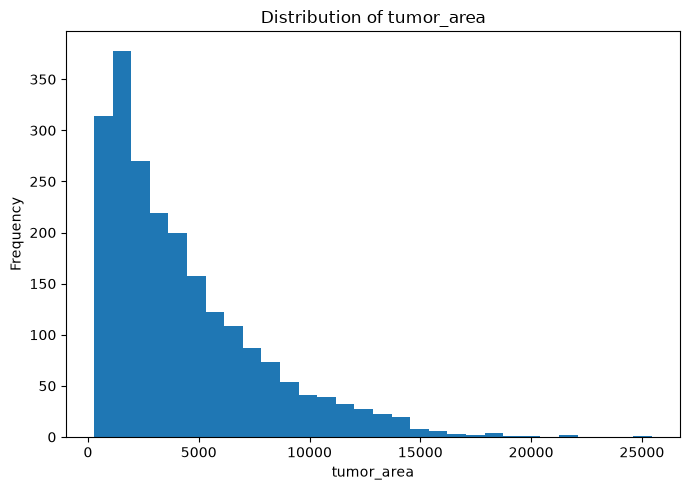

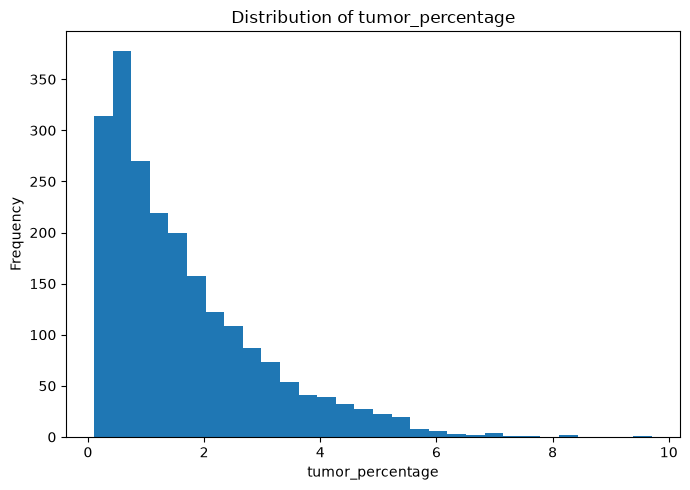

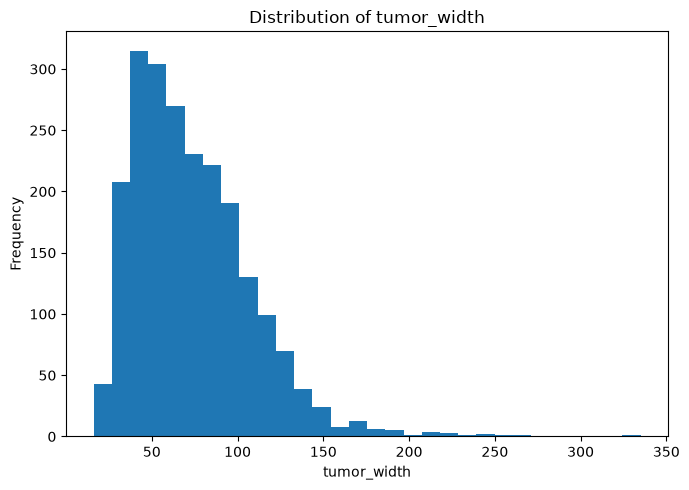

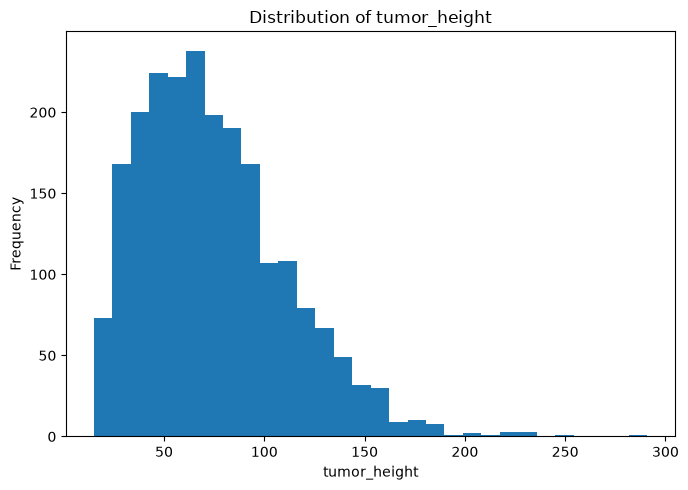

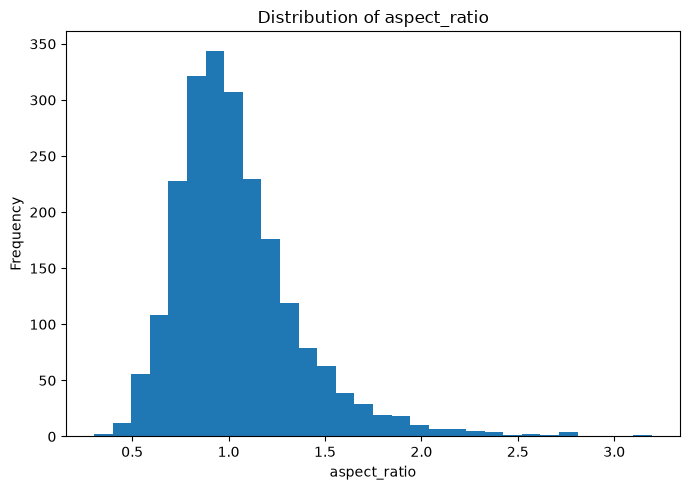

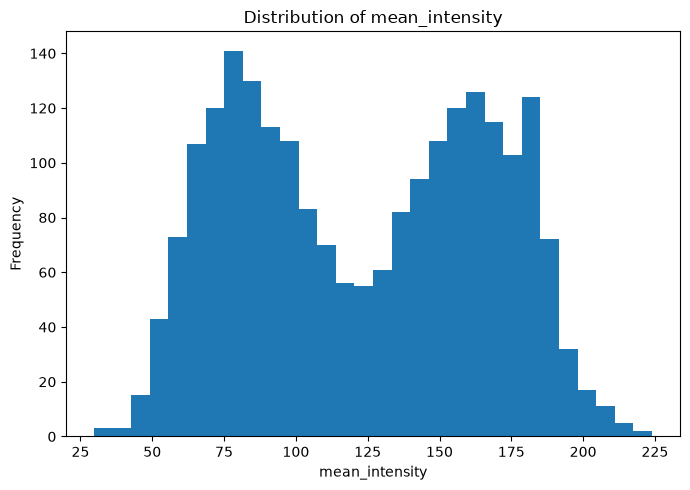

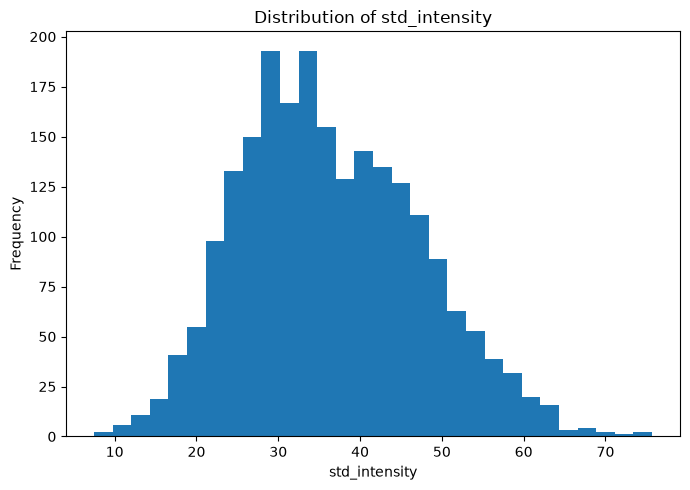

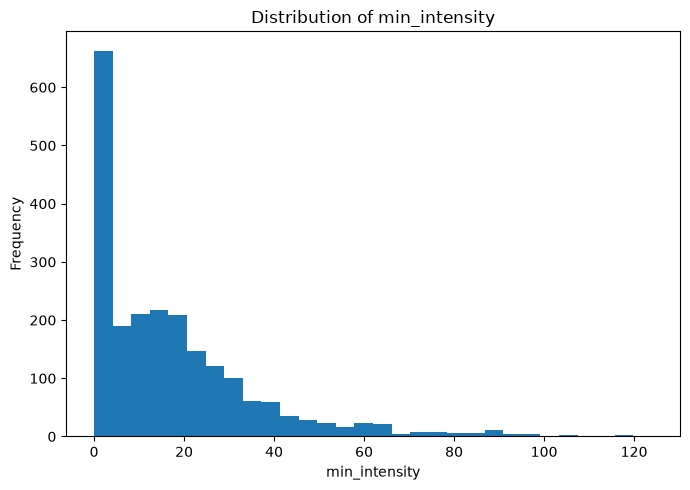

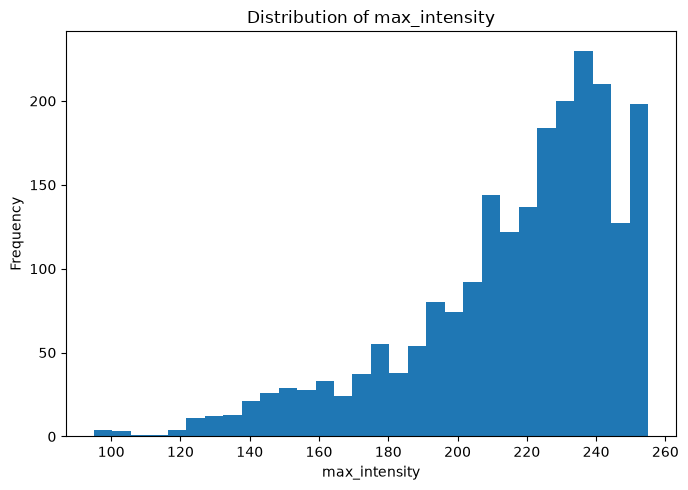

In [10]:
# Distribution of numerical features

import matplotlib.pyplot as plt

numerical_features = [
    "tumor_area",
    "tumor_percentage",
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

for feature in numerical_features:

    plt.figure(figsize=(7, 5))

    plt.hist(
        features_df[feature],
        bins=30
    )

    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {feature}")

    plt.tight_layout()
    plt.show()

### EDA Observations – Feature Distributions

The distribution plots show the following patterns:

- **Tumor area:** The distribution is strongly right-skewed. Most samples have relatively smaller tumor areas, while a smaller number of samples have substantially larger tumor areas.
- **Tumor percentage:** The distribution is right-skewed, with most images having a relatively low percentage of pixels occupied by the tumor.
- **Tumor width:** The distribution is positively skewed, with most tumor widths concentrated at lower values and fewer samples having very large widths.
- **Tumor height:** The distribution is also positively skewed, with most observations concentrated at lower-to-medium values and a long right tail.
- **Aspect ratio:** The values are mainly concentrated around the central range, with fewer observations at higher aspect ratios.
- **Mean intensity:** The distribution shows two prominent groups, indicating variation in the average MRI intensity characteristics of the tumor regions.
- **Standard deviation of intensity:** The distribution is approximately unimodal, with most values concentrated in the middle range and fewer observations at the extremes.
- **Minimum intensity:** The distribution contains a large concentration at low values and a long right tail.
- **Maximum intensity:** The values are concentrated toward the higher intensity range, with fewer observations at lower values.

Overall, several geometric features such as tumor area, width, and height show right-skewed distributions, while the intensity features exhibit different distribution patterns. These variations indicate that the engineered features capture diverse characteristics of the tumor regions and provide useful inputs for subsequent machine-learning analysis.

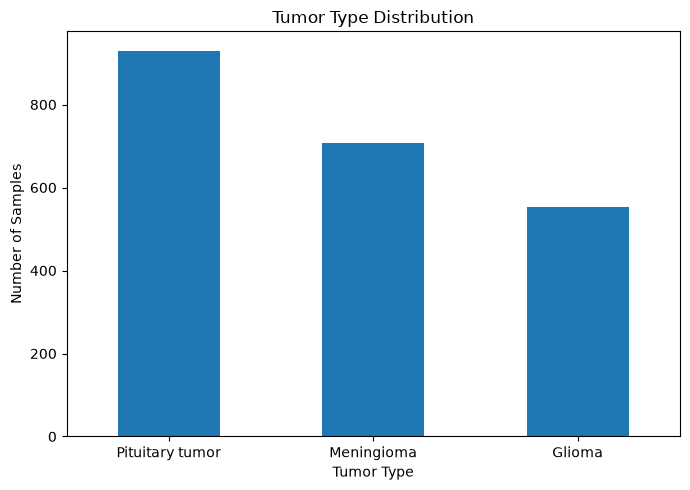

In [11]:
# Tumor type distribution

plt.figure(figsize=(7, 5))

features_df["tumor_type"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Tumor Type")
plt.ylabel("Number of Samples")
plt.title("Tumor Type Distribution")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### EDA Observation – Tumor Type Distribution

The tumor-type distribution shows the number of MRI samples available for each tumor category. The dataset contains three tumor classes: Glioma, Meningioma, and Pituitary tumor.

The distribution should be considered when interpreting classification performance, since differences in the number of samples between classes can influence model performance.

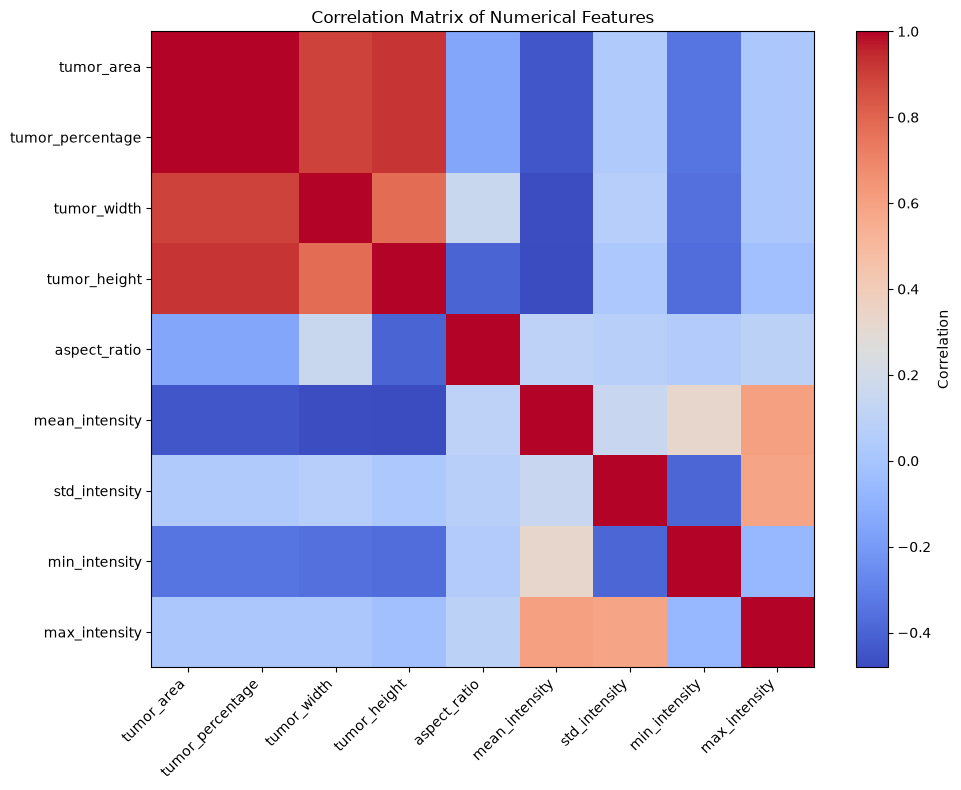

In [12]:
# Correlation analysis of numerical features

correlation_features = [
    "tumor_area",
    "tumor_percentage",
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

correlation_matrix = features_df[correlation_features].corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

### EDA Observation – Correlation Analysis

The correlation matrix shows strong relationships among several geometric tumor features.

Tumor area has a strong positive correlation with tumor percentage, tumor width, and tumor height. This is expected because larger tumor dimensions generally produce a larger segmented tumor region and therefore a greater tumor area and tumor percentage.

Tumor width and tumor height also show a positive relationship, indicating that the dimensions of the segmented tumor are related.

Among the intensity-based features, mean intensity shows a positive relationship with maximum intensity, while minimum intensity shows a weaker relationship with the other intensity features.

The geometric tumor features generally have weak relationships with the intensity-based features. This indicates that the engineered features capture different aspects of the MRI tumor regions, although some geometric features contain related information.

<Figure size 800x500 with 0 Axes>

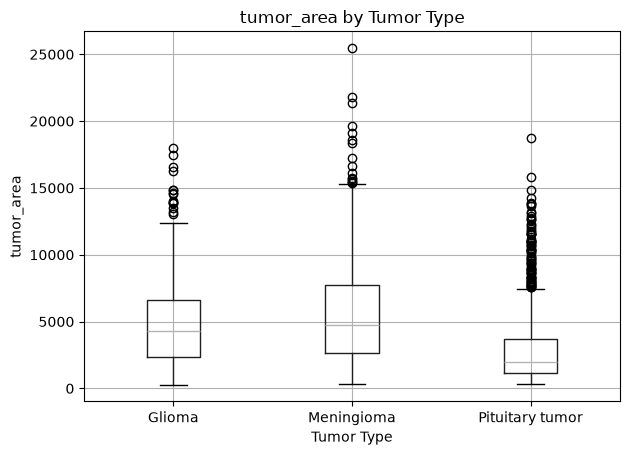

<Figure size 800x500 with 0 Axes>

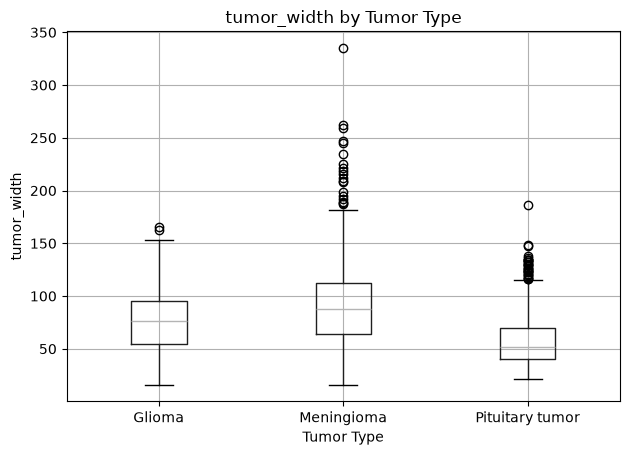

<Figure size 800x500 with 0 Axes>

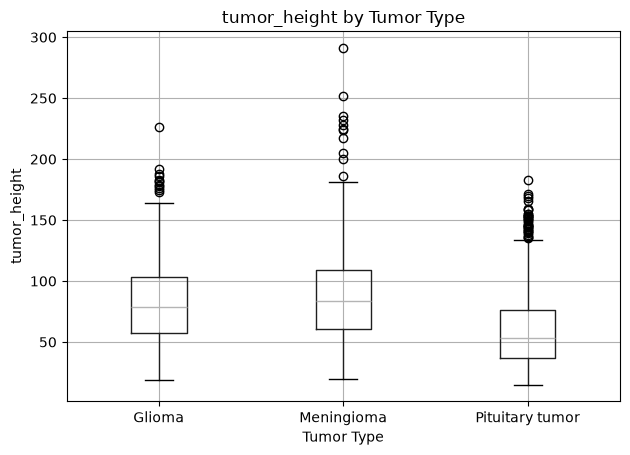

<Figure size 800x500 with 0 Axes>

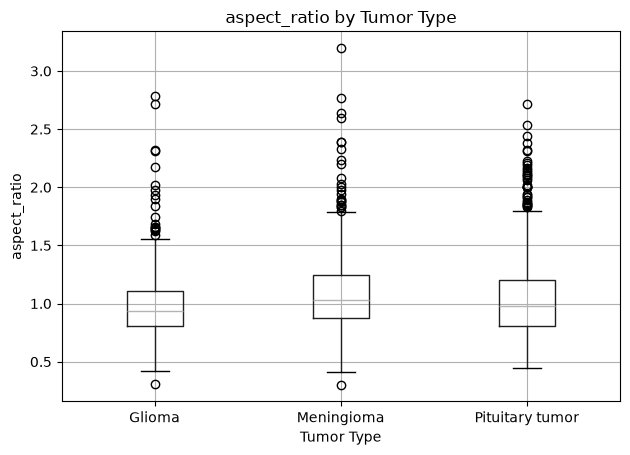

<Figure size 800x500 with 0 Axes>

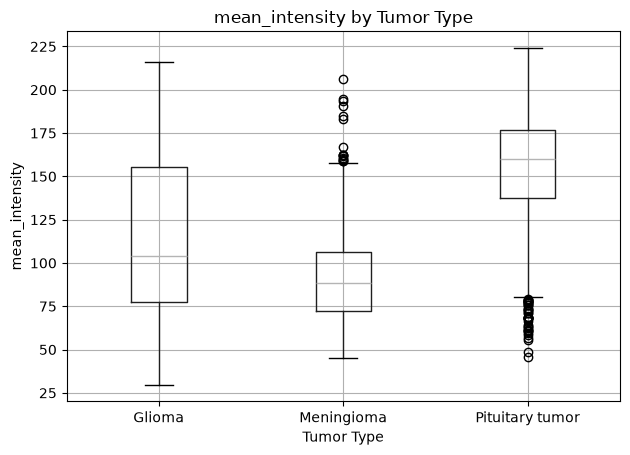

<Figure size 800x500 with 0 Axes>

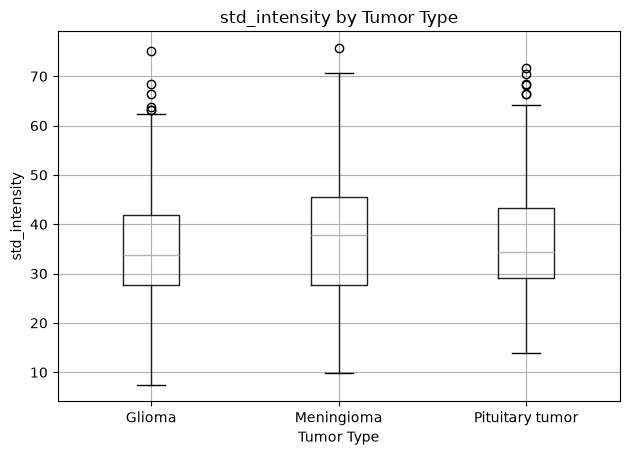

In [13]:
# Compare numerical features across tumor types

comparison_features = [
    "tumor_area",
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity"
]

for feature in comparison_features:

    plt.figure(figsize=(8, 5))

    features_df.boxplot(
        column=feature,
        by="tumor_type"
    )

    plt.title(f"{feature} by Tumor Type")
    plt.suptitle("")
    plt.xlabel("Tumor Type")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

### EDA Observation – Features Across Tumor Types

The boxplots show differences in the distributions of the engineered features across Glioma, Meningioma, and Pituitary tumor classes.

Meningioma generally shows higher tumor area, tumor width, and tumor height compared with the other tumor types. Pituitary tumors generally have smaller values for these geometric features, while Glioma lies between the two classes for several of these measurements.

The aspect ratio distributions overlap considerably across all three tumor types, indicating that this feature alone provides limited separation between the classes.

The mean intensity shows a more noticeable difference between classes. Pituitary tumors generally have higher mean intensity values, while Meningioma has lower typical mean intensity values. Glioma shows a wider spread of mean intensity values.

The standard deviation of intensity shows considerable overlap between the three classes, although the central ranges differ slightly.

Overall, the boxplots indicate that geometric and intensity-based features provide different levels of separation between tumor types. The combination of these features can therefore provide useful information for the classification models.

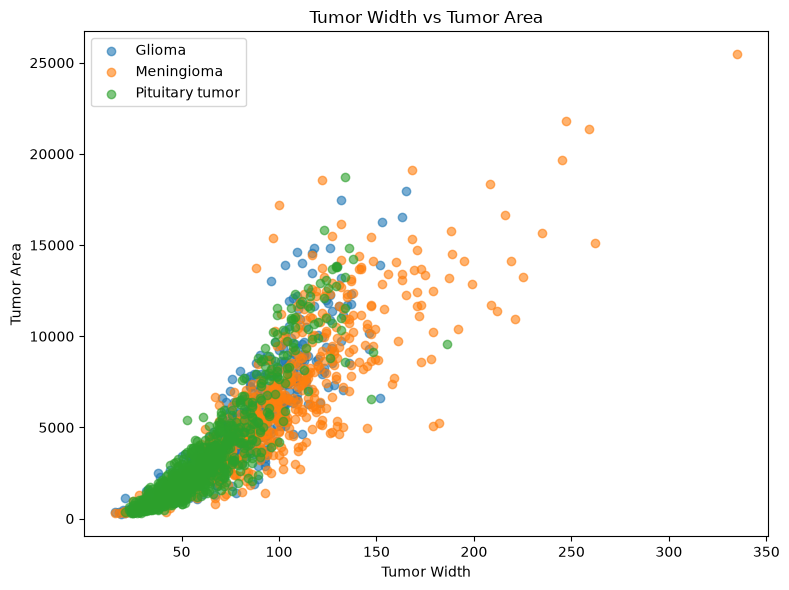

In [14]:
# Tumor dimensions vs tumor area

plt.figure(figsize=(8, 6))

for tumor_type in features_df["tumor_type"].unique():

    subset = features_df[
        features_df["tumor_type"] == tumor_type
    ]

    plt.scatter(
        subset["tumor_width"],
        subset["tumor_area"],
        label=tumor_type,
        alpha=0.6
    )

plt.xlabel("Tumor Width")
plt.ylabel("Tumor Area")
plt.title("Tumor Width vs Tumor Area")
plt.legend()

plt.tight_layout()
plt.show()

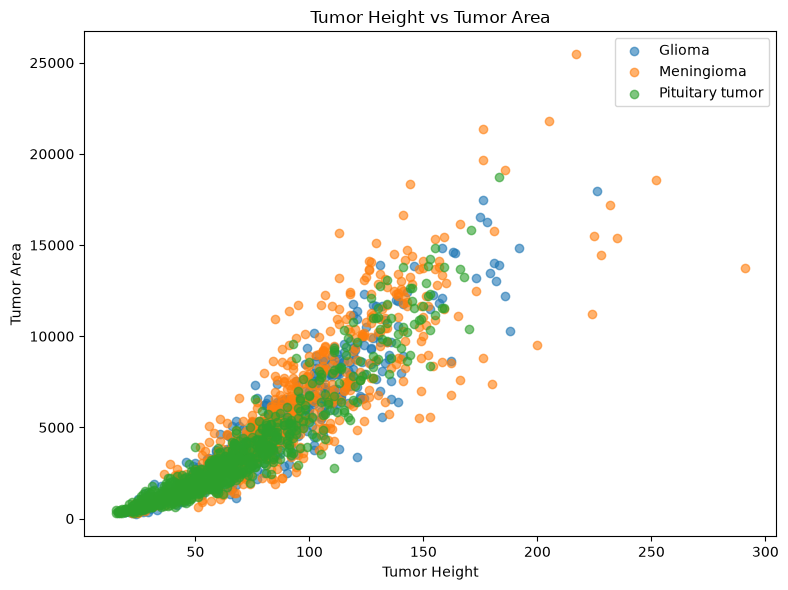

In [15]:
# Tumor height vs tumor area

plt.figure(figsize=(8, 6))

for tumor_type in features_df["tumor_type"].unique():

    subset = features_df[
        features_df["tumor_type"] == tumor_type
    ]

    plt.scatter(
        subset["tumor_height"],
        subset["tumor_area"],
        label=tumor_type,
        alpha=0.6
    )

plt.xlabel("Tumor Height")
plt.ylabel("Tumor Area")
plt.title("Tumor Height vs Tumor Area")
plt.legend()

plt.tight_layout()
plt.show()

### EDA Observation – Tumor Dimensions and Tumor Area

The scatter plots show a clear positive relationship between tumor dimensions and tumor area.

Tumor area generally increases as tumor width increases, indicating that wider segmented tumor regions tend to have larger areas. A similar positive relationship is observed between tumor height and tumor area.

Meningioma samples extend toward larger tumor dimensions and larger tumor areas, while the three tumor types show substantial overlap across the lower and middle ranges.

These relationships support the use of tumor width and tumor height as important predictors for tumor-area regression. However, the overlap between tumor types indicates that these features alone are not sufficient to completely distinguish the tumor classes.

In [7]:
# Save generated features as a CSV file

output_path = r"C:\ML PROJECT\DATASET\segmentation_features.csv"

features_df.to_csv(output_path, index=False)

print("Feature dataset saved successfully!")
print("File:", output_path)
print("Shape:", features_df.shape)

Feature dataset saved successfully!
File: C:\ML PROJECT\DATASET\segmentation_features.csv
Shape: (2192, 11)
